# End-to-End MLOps: Heart Disease Classification

**Purpose:** Demonstration of data acquisition, EDA, preprocessing, model selection, experiment tracking, reproducible artifacts, and prediction checks.

**Dataset:** UCI Heart Disease (dataset ID 45), downloaded through `ucimlrepo`.


## 1. Install dependencies


In [16]:
%pip -q install "ucimlrepo==0.0.7" "mlflow==2.19.0" "numpy>=1.26,<3" "pandas>=2.1,<3" "scikit-learn>=1.4,<1.7" "matplotlib>=3.8,<4" "seaborn>=0.13,<1" "joblib>=1.3,<2"

Note: you may need to restart the kernel to use updated packages.


## 2. Imports, configuration and reproducibility

We set seeds, create portable output folders, and define a small helper for saving plots. The `ARTIFACT_DIR` environment variable can override the default output location.

In [17]:
import os
import sys
import json
import platform
import warnings
import subprocess
from pathlib import Path
from datetime import datetime, timezone
import importlib.metadata as importlib_metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import mlflow
import mlflow.sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, RocCurveDisplay
)
from ucimlrepo import fetch_ucirepo

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
np.random.seed(SEED)

ARTIFACT_DIR = Path(os.environ.get("ARTIFACT_DIR", "heart_disease_mlops_artifacts")).resolve()
DATA_DIR = ARTIFACT_DIR / "data"
MODEL_DIR = ARTIFACT_DIR / "models"
REPORT_DIR = ARTIFACT_DIR / "reports"
PLOT_DIR = REPORT_DIR / "plots"
for folder in (ARTIFACT_DIR, DATA_DIR, MODEL_DIR, REPORT_DIR, PLOT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

def save_plot(filename, dpi=150):
    path = PLOT_DIR / filename
    plt.tight_layout()
    plt.savefig(path, dpi=dpi, bbox_inches="tight")
    print(f"Saved plot: {path}")
    return path

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Artifact directory:", ARTIFACT_DIR)

Python: 3.13.15
Platform: Linux-6.18.48+-x86_64-with-glibc2.39
Artifact directory: /kaggle/working/heart_disease_mlops_artifacts


## 3. Acquire the UCI Heart Disease dataset

The original UCI data has multiple target values (`num` 0–4). We retain the original target for traceability and create a binary target: `0 = absence`, `1 = presence` (any original value greater than zero). This binary mapping is a modelling choice.

In [18]:
uci_heart = fetch_ucirepo(id=45)
X_raw = uci_heart.data.features.copy()
y_raw = uci_heart.data.targets.copy()

print("Feature shape:", X_raw.shape)
print("Target shape:", y_raw.shape)
print("Feature columns:", list(X_raw.columns))
display(X_raw.head())
display(y_raw.head())

# Save a raw snapshot where possible to support reproducibility/audit.
raw_features_path = DATA_DIR / "uci_heart_features_raw.csv"
raw_target_path = DATA_DIR / "uci_heart_target_raw.csv"
X_raw.to_csv(raw_features_path, index=False)
y_raw.to_csv(raw_target_path, index=False)
print("Saved raw feature and target snapshots.")

Feature shape: (303, 13)
Target shape: (303, 1)
Feature columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0


,num
0,0
1,2
2,1
3,0
4,0


Saved raw feature and target snapshots.


## 4. Validate and clean the data

This section checks the target column, normalizes feature names, converts numeric-looking columns to numeric values where possible, removes rows with missing target labels, and records the binary class distribution. Missing **feature** values are not dropped; they are handled inside the preprocessing pipeline to avoid losing data unnecessarily.

In [19]:
if y_raw.shape[1] != 1:
    raise ValueError(f"Expected one target column, got {list(y_raw.columns)}")

target_col = y_raw.columns[0]
y_original = pd.to_numeric(y_raw[target_col], errors="coerce")
valid_target = y_original.notna()

X = X_raw.loc[valid_target].copy()
y_original = y_original.loc[valid_target].astype(int)
X.columns = [str(c).strip().lower().replace(" ", "_") for c in X.columns]
y = (y_original > 0).astype(int).rename("target")

# Convert feature columns to numeric where possible, keeping unconvertible values as missing.
for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors="coerce")

if X.empty:
    raise ValueError("No rows remain after target validation.")
if y.nunique() != 2:
    raise ValueError(f"Expected two target classes after binarization, got {sorted(y.unique())}")

cleaned = X.copy()
cleaned["target"] = y
cleaned.to_csv(DATA_DIR / "heart_disease_cleaned.csv", index=False)

print("Cleaned feature shape:", X.shape)
print("Binary target distribution:")
display(y.value_counts().rename(index={0:"absence", 1:"presence"}).to_frame("count"))
print("Missing values per feature:")
display(X.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

Cleaned feature shape: (303, 13)
Binary target distribution:


,count
target,
absence,164
presence,139


Missing values per feature:


,missing_count
ca,4
thal,2
cp,0
sex,0
age,0
chol,0
trestbps,0
fbs,0
restecg,0
exang,0


## 5. Exploratory Data Analysis (EDA)

The following tables and figures are generated from the downloaded dataset.

,missing_count,missing_percent
ca,4,1.32
thal,2,0.66
cp,0,0.00
sex,0,0.00
age,0,0.00
chol,0,0.00
trestbps,0,0.00
fbs,0,0.00
restecg,0,0.00
exang,0,0.00


Saved plot: /kaggle/working/heart_disease_mlops_artifacts/reports/plots/class_balance.png


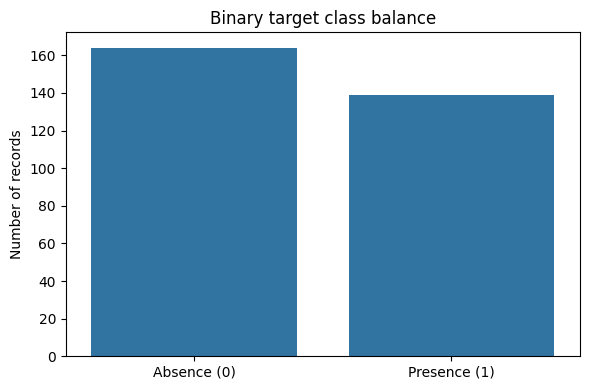

Saved plot: /kaggle/working/heart_disease_mlops_artifacts/reports/plots/correlation_heatmap.png


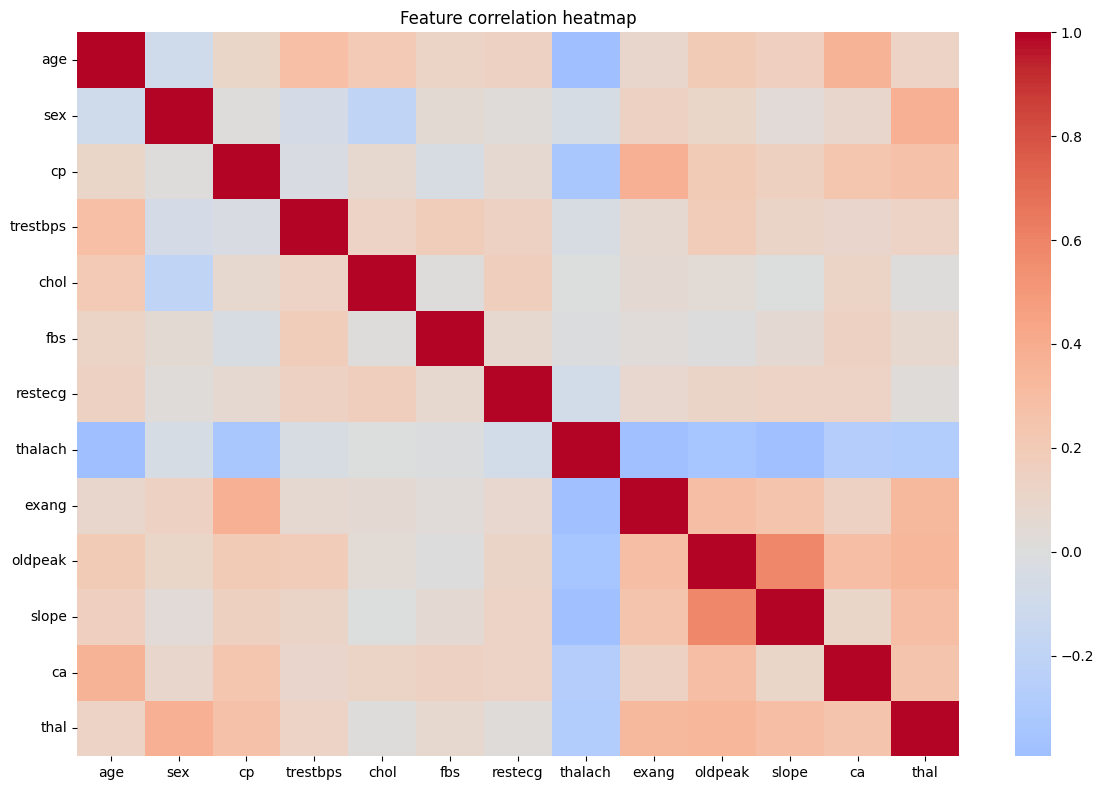

Saved plot: /kaggle/working/heart_disease_mlops_artifacts/reports/plots/feature_histograms.png


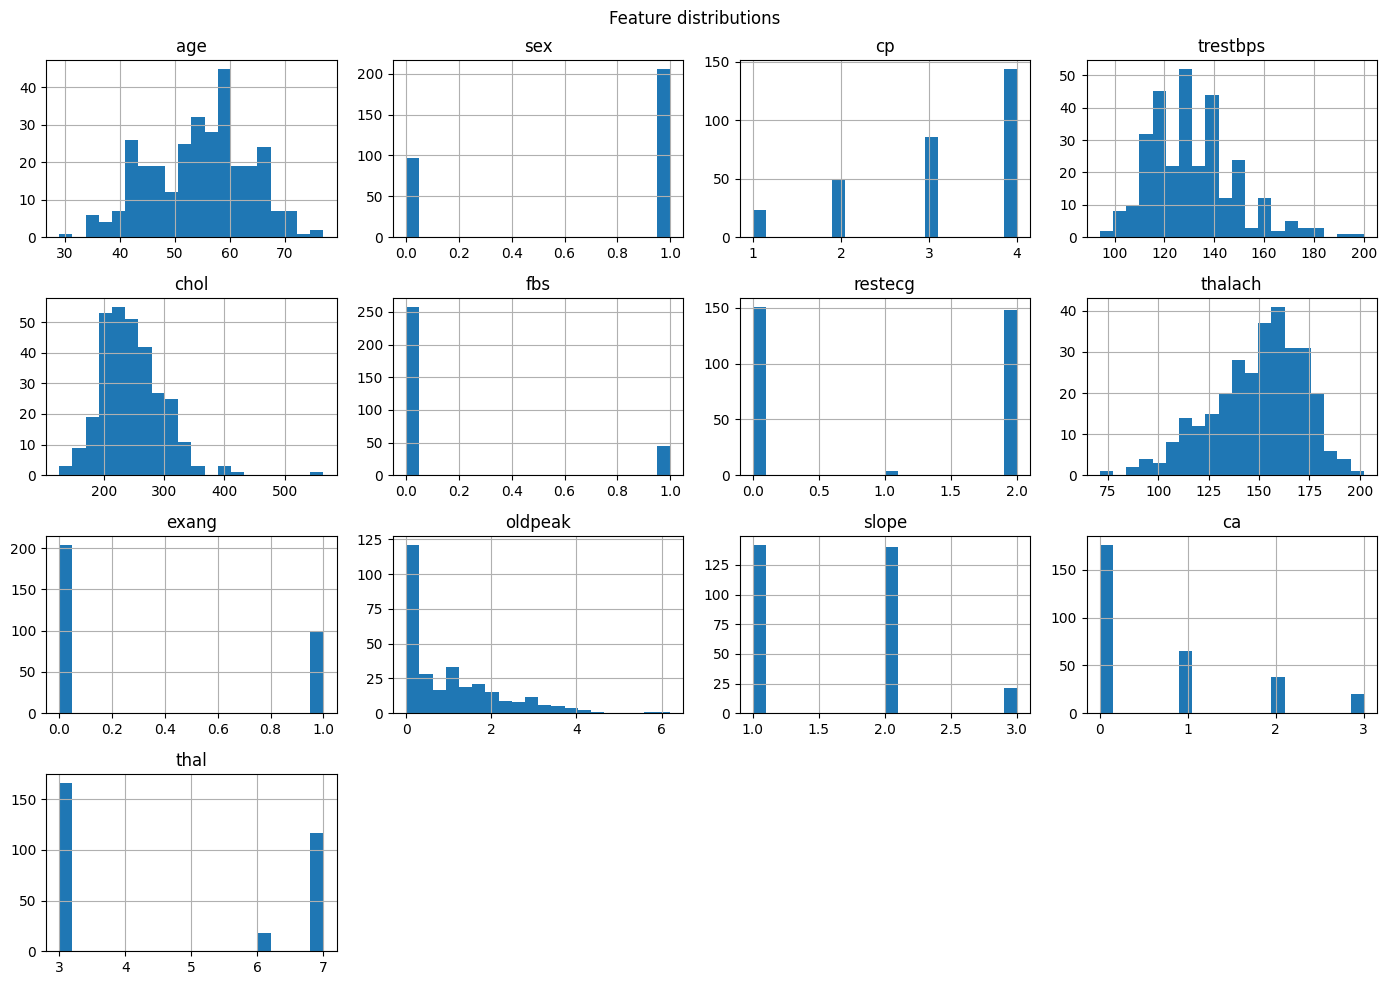

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [20]:
missing_summary = pd.DataFrame({
    "missing_count": X.isna().sum(),
    "missing_percent": (X.isna().mean() * 100).round(2),
}).sort_values("missing_count", ascending=False)
display(missing_summary)
missing_summary.to_csv(REPORT_DIR / "missing_values.csv")

class_counts = y.value_counts().sort_index()
plt.figure(figsize=(6,4))
sns.barplot(x=["Absence (0)", "Presence (1)"], y=[class_counts.get(0,0), class_counts.get(1,0)])
plt.title("Binary target class balance")
plt.ylabel("Number of records")
save_plot("class_balance.png")
plt.show()

plt.figure(figsize=(12,8))
sns.heatmap(X.corr(numeric_only=True), cmap="coolwarm", center=0, annot=False)
plt.title("Feature correlation heatmap")
save_plot("correlation_heatmap.png")
plt.show()

numeric_cols_all = X.select_dtypes(include=np.number).columns.tolist()
X[numeric_cols_all].hist(figsize=(14,10), bins=20)
plt.suptitle("Feature distributions")
save_plot("feature_histograms.png")
plt.show()

display(X.describe(include="all").T)

## 6. Feature engineering and preprocessing

Several columns are numeric codes for categories. We treat the known coded fields as categorical when present and remaining columns as numeric. Imputation and scaling/one-hot encoding live inside the scikit-learn pipeline, so the same transformations are learned on training data and reused at inference time. This avoids preprocessing leakage from the held-out test set.

In [21]:
known_categorical = {"sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"}
categorical_cols = [c for c in X.columns if c in known_categorical]
numeric_cols = [c for c in X.columns if c not in categorical_cols]

# Ensure numeric columns are truly numeric and categorical fields are consistently represented.
for col in numeric_cols:
    X[col] = pd.to_numeric(X[col], errors="coerce")
for col in categorical_cols:
    # Keep categorical values as strings so one-hot encoding handles numeric category codes consistently.
    X[col] = X[col].map(lambda v: str(int(v)) if pd.notna(v) and float(v).is_integer() else (str(v) if pd.notna(v) else np.nan))

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols),
], remainder="drop")

print("Categorical columns:", categorical_cols)
print("Numeric columns:", numeric_cols)
print("Feature count:", len(X.columns))

Categorical columns: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
Numeric columns: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Feature count: 13


## 7. Train/test split and cross-validated model selection

We use a stratified 80/20 hold-out split with a fixed seed and stratified 5-fold cross-validation on the training data. The test set is held back for final evaluation. Model selection uses mean CV ROC-AUC, a threshold-independent metric for binary classification.

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

model_specs = {
    "logistic_regression": (
        LogisticRegression(max_iter=3000, random_state=SEED, solver="liblinear"),
        {"classifier__C": [0.1, 1.0, 10.0]},
    ),
    "random_forest": (
        RandomForestClassifier(random_state=SEED, class_weight="balanced"),
        {
            "classifier__n_estimators": [200, 400],
            "classifier__max_depth": [None, 5, 10],
            "classifier__min_samples_leaf": [1, 2],
        },
    ),
}

fitted_searches = {}
for name, (estimator, param_grid) in model_specs.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", estimator),
    ])
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
    )
    search.fit(X_train, y_train)
    fitted_searches[name] = search
    print(f"{name}: best CV ROC-AUC={search.best_score_:.4f}; params={search.best_params_}")

logistic_regression: best CV ROC-AUC=0.9025; params={'classifier__C': 1.0}
random_forest: best CV ROC-AUC=0.9016; params={'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 200}


## 8. Evaluate candidates on the held-out test set

Metrics are computed on the untouched test split. The selected model is the candidate with the highest cross-validated ROC-AUC. Test-set performance is reported for comparison, not used to select hyperparameters.

In [23]:
results = []
predictions = {}
probabilities = {}

for model_name, search in fitted_searches.items():
    best_model = search.best_estimator_
    pred = best_model.predict(X_test)
    prob = best_model.predict_proba(X_test)[:, 1]
    predictions[model_name] = pred
    probabilities[model_name] = prob
    results.append({
        "model": model_name,
        "best_cv_roc_auc": float(search.best_score_),
        "test_accuracy": float(accuracy_score(y_test, pred)),
        "test_precision": float(precision_score(y_test, pred, zero_division=0)),
        "test_recall": float(recall_score(y_test, pred, zero_division=0)),
        "test_f1": float(f1_score(y_test, pred, zero_division=0)),
        "test_roc_auc": float(roc_auc_score(y_test, prob)),
        "best_params": json.dumps(search.best_params_, sort_keys=True),
    })

results_df = pd.DataFrame(results).sort_values("best_cv_roc_auc", ascending=False).reset_index(drop=True)
display(results_df)
results_df.to_csv(REPORT_DIR / "model_comparison.csv", index=False)
with open(REPORT_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(results_df.drop(columns=["best_params"]).to_dict(orient="records"), f, indent=2)

selected_name = results_df.loc[0, "model"]
selected_model = fitted_searches[selected_name].best_estimator_
print("Selected model (highest CV ROC-AUC):", selected_name)

,model,best_cv_roc_auc,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,best_params
0,logistic_regression,0.902493,0.885246,0.83871,0.928571,0.881356,0.966450,"{""classifier__C"": 1.0}"
1,random_forest,0.901610,0.901639,0.84375,0.964286,0.900000,0.953463,"{""classifier__max_depth"": 10, ""classifier__min..."


Selected model (highest CV ROC-AUC): logistic_regression


Saved plot: /kaggle/working/heart_disease_mlops_artifacts/reports/plots/confusion_matrix_logistic_regression.png


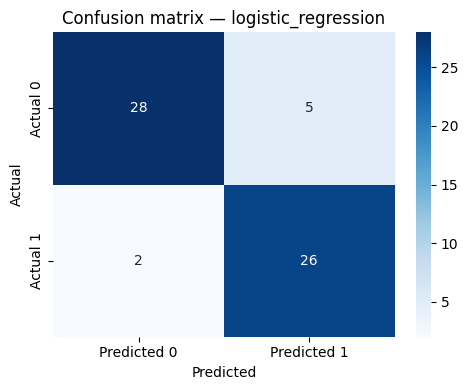

Classification report — logistic_regression
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61

Saved plot: /kaggle/working/heart_disease_mlops_artifacts/reports/plots/confusion_matrix_random_forest.png


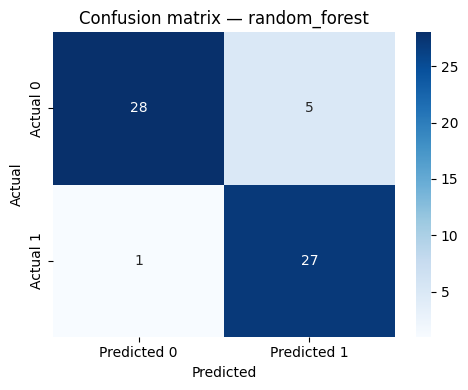

Classification report — random_forest
              precision    recall  f1-score   support

           0       0.97      0.85      0.90        33
           1       0.84      0.96      0.90        28

    accuracy                           0.90        61
   macro avg       0.90      0.91      0.90        61
weighted avg       0.91      0.90      0.90        61

Saved plot: /kaggle/working/heart_disease_mlops_artifacts/reports/plots/roc_curves.png


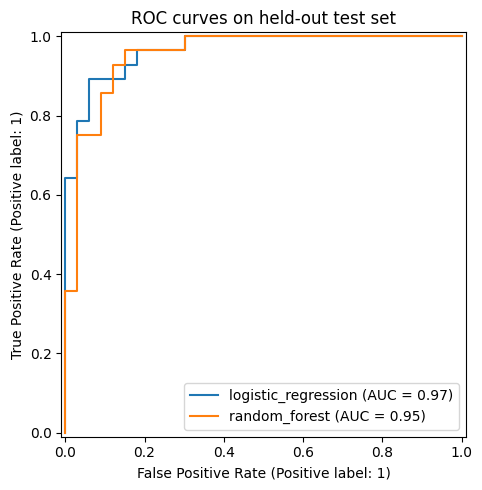

In [24]:
for model_name in fitted_searches:
    cm = confusion_matrix(y_test, predictions[model_name], labels=[0,1])
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Predicted 0", "Predicted 1"],
                yticklabels=["Actual 0", "Actual 1"])
    plt.title(f"Confusion matrix — {model_name}")
    plt.ylabel("Actual")
    plt.xlabel("Predicted")
    save_plot(f"confusion_matrix_{model_name}.png")
    plt.show()
    print(f"Classification report — {model_name}")
    print(classification_report(y_test, predictions[model_name], zero_division=0))

plt.figure(figsize=(7,5))
for model_name, prob in probabilities.items():
    RocCurveDisplay.from_predictions(y_test, prob, name=model_name, ax=plt.gca())
plt.title("ROC curves on held-out test set")
save_plot("roc_curves.png")
plt.show()

## 9. MLflow experiment tracking

Each candidate is logged in its own MLflow run. The run records the best hyperparameters, CV ROC-AUC, held-out test metrics, model artifact, comparison table and plots. Metric names are explicit and consistent with the results table.

In [25]:
mlflow.set_tracking_uri((ARTIFACT_DIR / "mlruns").as_uri())
mlflow.set_experiment("heart-disease-classification")

metric_cols = ["best_cv_roc_auc", "test_accuracy", "test_precision", "test_recall", "test_f1", "test_roc_auc"]
for model_name, search in fitted_searches.items():
    row = results_df.loc[results_df["model"] == model_name].iloc[0]
    with mlflow.start_run(run_name=model_name):
        mlflow.set_tags({
            "dataset": "UCI Heart Disease (id=45)",
            "task": "binary_classification",
            "selected_for_final_artifact": str(model_name == selected_name).lower(),
            "random_seed": str(SEED),
        })
        mlflow.log_param("model_name", model_name)
        mlflow.log_param("cv_folds", 5)
        mlflow.log_param("test_size", 0.20)
        mlflow.log_param("selection_metric", "best_cv_roc_auc")
        for key, value in search.best_params_.items():
            mlflow.log_param(f"best_{key}", str(value))
        for metric in metric_cols:
            mlflow.log_metric(metric, float(row[metric]))
        mlflow.log_artifact(str(REPORT_DIR / "model_comparison.csv"), artifact_path="reports")
        for plot_path in PLOT_DIR.glob("*.png"):
            mlflow.log_artifact(str(plot_path), artifact_path="plots")
        mlflow.sklearn.log_model(
            sk_model=search.best_estimator_,
            artifact_path="model",
            registered_model_name=None,
        )
        print(f"Logged MLflow run for {model_name}")

2026/10/19 17:38:20 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


Logged MLflow run for logistic_regression


2026/10/19 17:38:25 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


Logged MLflow run for random_forest


In [26]:
# Verify that MLflow has two candidate runs and that expected metrics were logged.
experiment = mlflow.get_experiment_by_name("heart-disease-classification")
runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    order_by=["start_time DESC"],
)
display(runs[["run_id", "tags.mlflow.runName", "metrics.best_cv_roc_auc",
              "metrics.test_accuracy", "metrics.test_roc_auc"]])
print("Runs found:", len(runs))

,run_id,tags.mlflow.runName,metrics.best_cv_roc_auc,metrics.test_accuracy,metrics.test_roc_auc
0,69063573f67442debc77cfa3baf0d632,random_forest,0.901610,0.901639,0.953463
1,855d4fa96ff44e168fc9ba43c1536577,logistic_regression,0.902493,0.885246,0.966450
2,36f2a4b2a8b646a2a1ae68a800cf86a8,random_forest,0.901610,0.901639,0.953463
3,dcfc9e6c03564d69971166a23a9aad37,logistic_regression,0.902493,0.885246,0.966450


Runs found: 4


## 10. Save the final model and metadata

The exported artifact is the **full fitted pipeline** (imputation, scaling/encoding and classifier), not just the estimator. This is important because inference must apply the same transformations as training.

In [27]:
model_path = MODEL_DIR / "model.joblib"
joblib.dump(selected_model, model_path)

metadata = {
    "project": "Heart Disease Classification MLOps Assignment",
    "dataset": "UCI Heart Disease",
    "uci_dataset_id": 45,
    "task": "binary classification",
    "target_definition": "0 = original target 0 (absence); 1 = original target > 0 (presence)",
    "selected_model": selected_name,
    "selection_metric": "mean 5-fold cross-validation ROC-AUC on training split",
    "random_seed": SEED,
    "test_size": 0.20,
    "feature_names": list(X.columns),
    "categorical_features": categorical_cols,
    "numeric_features": numeric_cols,
    "metrics": results_df.loc[results_df["model"] == selected_name].drop(columns=["best_params"]).iloc[0].to_dict(),
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "artifact": str(model_path.relative_to(ARTIFACT_DIR)),
}
with open(MODEL_DIR / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, default=str)

print("Saved model:", model_path)
print("Saved metadata:", MODEL_DIR / "metadata.json")

Saved model: /kaggle/working/heart_disease_mlops_artifacts/models/model.joblib
Saved metadata: /kaggle/working/heart_disease_mlops_artifacts/models/metadata.json


## 11. Prediction smoke test and sample API payload

We test a prediction after saving and reloading the model. 

In [28]:
reloaded_model = joblib.load(model_path)
sample_features = X_test.iloc[[0]].copy()
prediction = int(reloaded_model.predict(sample_features)[0])
probability = float(reloaded_model.predict_proba(sample_features)[0, 1])

# Verify saved/reloaded model behavior is consistent with the in-memory model.
assert prediction == int(selected_model.predict(sample_features)[0]), "Prediction mismatch after reload"
assert np.isclose(probability, float(selected_model.predict_proba(sample_features)[0, 1])), "Probability mismatch after reload"

sample_payload = {}
for col in X.columns:
    val = sample_features.iloc[0][col]
    if pd.isna(val):
        sample_payload[col] = None
    elif col in categorical_cols:
        sample_payload[col] = str(val)
    else:
        sample_payload[col] = float(val)

with open(REPORT_DIR / "sample_prediction_payload.json", "w", encoding="utf-8") as f:
    json.dump(sample_payload, f, indent=2, allow_nan=False)

print("Smoke test passed.")
print("Sample model output (software test only):", {"prediction": prediction, "probability_presence": round(probability, 4)})
display(pd.DataFrame([sample_payload]))

Smoke test passed.
Sample model output (software test only): {'prediction': 0, 'probability_presence': 0.2091}


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,59.0,1,4,138.0,271.0,0,2,182.0,0,0.0,1,0,3


## 12. Environment manifest and reproducibility record

This cell captures the runtime versions and important training settings.

In [29]:
package_names = ["numpy", "pandas", "scikit-learn", "matplotlib", "seaborn", "mlflow", "ucimlrepo", "joblib"]
packages = {}
for package in package_names:
    try:
        packages[package] = importlib_metadata.version(package)
    except importlib_metadata.PackageNotFoundError:
        packages[package] = None

environment_manifest = {
    "python": sys.version,
    "platform": platform.platform(),
    "packages": packages,
    "random_seed": SEED,
    "cv": {"strategy": "StratifiedKFold", "n_splits": 5, "shuffle": True, "random_state": SEED},
    "train_test_split": {"test_size": 0.20, "random_state": SEED, "stratify": True},
    "artifact_directory": str(ARTIFACT_DIR),
}
with open(REPORT_DIR / "environment_manifest.json", "w", encoding="utf-8") as f:
    json.dump(environment_manifest, f, indent=2)

print(json.dumps(environment_manifest, indent=2))

{
  "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]",
  "platform": "Linux-6.18.48+-x86_64-with-glibc2.39",
  "packages": {
    "numpy": "2.1.3",
    "pandas": "2.3.3",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "seaborn": "0.13.2",
    "mlflow": "2.19.0",
    "ucimlrepo": "0.0.7",
    "joblib": "1.6.0"
  },
  "random_seed": 42,
  "cv": {
    "strategy": "StratifiedKFold",
    "n_splits": 5,
    "shuffle": true,
    "random_state": 42
  },
  "train_test_split": {
    "test_size": 0.2,
    "random_state": 42,
    "stratify": true
  },
  "artifact_directory": "/kaggle/working/heart_disease_mlops_artifacts"
}


## 13. Final artifact inventory and completion checks

Confirm the core outputs exist. 

In [30]:
expected_files = [
    DATA_DIR / "heart_disease_cleaned.csv",
    REPORT_DIR / "missing_values.csv",
    REPORT_DIR / "model_comparison.csv",
    REPORT_DIR / "metrics.json",
    REPORT_DIR / "sample_prediction_payload.json",
    REPORT_DIR / "environment_manifest.json",
    MODEL_DIR / "model.joblib",
    MODEL_DIR / "metadata.json",
]
artifact_check = pd.DataFrame({
    "path": [str(p.relative_to(ARTIFACT_DIR)) for p in expected_files],
    "exists": [p.exists() for p in expected_files],
    "size_bytes": [p.stat().st_size if p.exists() else None for p in expected_files],
})
display(artifact_check)
if not artifact_check["exists"].all():
    raise RuntimeError("One or more expected artifacts were not generated.")
print(f"Notebook pipeline completed. Artifacts: {ARTIFACT_DIR}")

,path,exists,size_bytes
0,data/heart_disease_cleaned.csv,True,12475
1,reports/missing_values.csv,True,184
2,reports/model_comparison.csv,True,465
3,reports/metrics.json,True,538
4,reports/sample_prediction_payload.json,True,212
5,reports/environment_manifest.json,True,645
6,models/model.joblib,True,6118
7,models/metadata.json,True,1213


Notebook pipeline completed. Artifacts: /kaggle/working/heart_disease_mlops_artifacts
